# Per-mode fluxes and the pybhpt cross-validation gate

Phase 5, increment A: gravitational-wave **energy and angular-momentum
fluxes per Teukolsky mode**, batched (`hblteuk.jax.flux_modes`), validated
against an independent implementation — **pybhpt** (GSL ODE integration of
the radial equation with asymptotic boundary conditions, and its own
adaptive-quadrature source integrator).

The load-bearing result: hblteuk's hyperboloidal amplitudes equal pybhpt's
Boyer–Lindquist amplitudes **in magnitude and phase** — the two codes share
the Teukolsky normalization exactly, so pybhpt's flux formulas apply
verbatim. Reference data: `tests/golden/pybhpt_reference_v1.npz`
(regenerate with `tests/generate_pybhpt_reference.py`). Notes:
`dev/PHASE5A.md`. Sections assert their checks.

In [1]:
import pathlib
import numpy as np
import matplotlib.pyplot as plt

from hblteuk.geo import MiniGeo
from hblteuk.jax import solve_mode_table, flux_modes

C = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]  # Okabe-Ito, fixed order
ref = np.load(pathlib.Path("..") / "tests" / "golden" / "pybhpt_reference_v1.npz")
COLS = dict(l=0, m=1, n=2, omega=3, lam=4, zin_re=5, zin_im=6,
            zup_re=7, zup_im=8, edot_i=9, edot_h=10, ldot_i=11, ldot_h=12)
print("pybhpt reference:", {k: ref[k].shape for k in ref.files})

pybhpt reference: {'ecc_params': (4,), 'ecc_table': (10, 13), 'circ_params': (4,), 'circ_table': (4, 13)}


## 1. The amplitude-normalization gate

Same eccentric orbit, same modes, two completely different methods
(pseudospectral collocation + FFT source integration here vs pybhpt's
GSL ODE integration + adaptive quadrature).

worst: In 3.2e-10, Up 3.7e-09


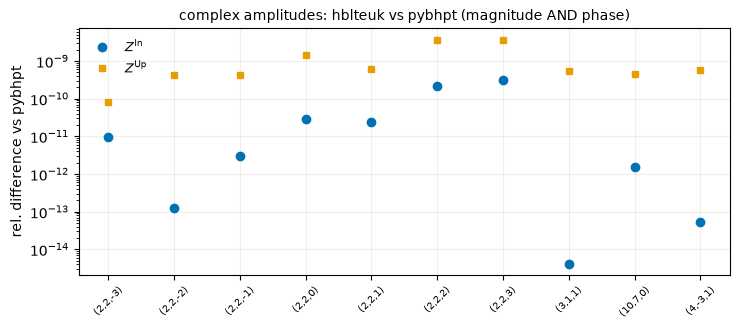

In [9]:
table = ref["ecc_table"]
orbit = MiniGeo(*ref["ecc_params"])
sol = solve_mode_table(orbit, -2,
                       table[:, COLS["l"]].astype(int),
                       table[:, COLS["m"]].astype(int),
                       table[:, COLS["n"]].astype(int))
zin_ref = table[:, COLS["zin_re"]] + 1j * table[:, COLS["zin_im"]]
zup_ref = table[:, COLS["zup_re"]] + 1j * table[:, COLS["zup_im"]]
amps = np.asarray(sol.amplitudes)

rel_in = np.abs(amps[:, 0] - zin_ref) / np.abs(zin_ref)
rel_up = np.abs(amps[:, 1] - zup_ref) / np.abs(zup_ref)
assert rel_in.max() < 1e-7 and rel_up.max() < 1e-7

labels = [f"({int(r[0])},{int(r[1])},{int(r[2])})" for r in table]
x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.semilogy(x, np.maximum(rel_in, 1e-17), "o", color=C[0], label=r"$Z^{\rm In}$")
ax.semilogy(x, np.maximum(rel_up, 1e-17), "s", color=C[1], ms=4, label=r"$Z^{\rm Up}$")
ax.set_xticks(x, labels, rotation=45, fontsize=7)
ax.set_ylabel("rel. difference vs pybhpt")
ax.set_title("complex amplitudes: hblteuk vs pybhpt (magnitude AND phase)",
             fontsize=10)
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()
print(f"worst: In {rel_in.max():.1e}, Up {rel_up.max():.1e}")

In [13]:
sol.amplitudes, sol.errors

(Array([[-1.70081328e-07-1.98562020e-08j,  8.15971089e-09+6.42298328e-10j],
        [-4.08220884e-06-7.15658578e-07j, -3.31541304e-07+3.28077243e-08j],
        [ 1.65728446e-04+3.87710715e-05j,  7.86343541e-05-1.55660933e-05j],
        [-9.03308952e-04-2.65344096e-04j, -7.43247047e-04+1.96060056e-04j],
        [-7.26403622e-04-2.56667865e-04j, -7.52059313e-04+2.31840201e-04j],
        [-3.65443591e-04-1.51348161e-04j, -4.47746799e-04+1.50313378e-04j],
        [-1.48865524e-04-7.09794472e-05j, -2.07895352e-04+7.24254807e-05j],
        [-5.68748921e-05-4.06018951e-05j, -6.79421949e-07-2.06266347e-06j],
        [ 1.22323559e-13-7.11401293e-13j,  4.24811926e-10+1.54272904e-10j],
        [-3.64412003e-07+3.45860986e-07j,  5.87270291e-07-1.32173899e-06j]],      dtype=complex128),
 Array([[2.17185736e-11, 3.09574743e-13],
        [7.37717346e-13, 2.34267561e-14],
        [1.71522292e-14, 5.09762716e-15],
        [2.94137591e-15, 3.47196074e-15],
        [3.38180736e-15, 1.15769526e-14],
     

## 2. Per-mode fluxes vs pybhpt

$\dot E^\infty = |Z^{\rm Up}|^2/4\pi\omega^2$,
$\dot E^H = \alpha_{\ell m\omega} |Z^{\rm In}|^2/4\pi\omega^2$,
$\dot L = (m/\omega)\dot E$ — batched elementwise.

all four flux channels match pybhpt to < 1e-7


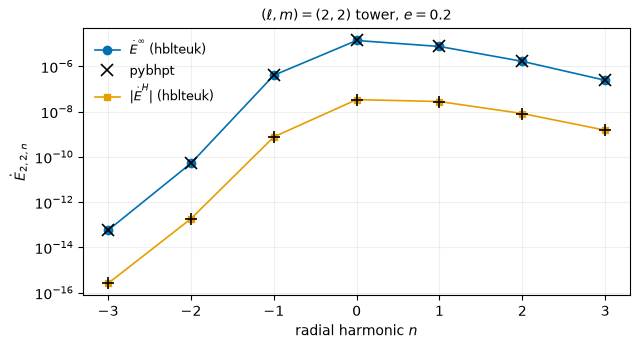

In [3]:
fx = flux_modes(sol.amplitudes, sol.m, sol.omega, sol.eigenvalues, orbit.a)
Edot = np.asarray(fx.Edot); Ldot = np.asarray(fx.Ldot)
for got, col in [(Edot[:, 0], "edot_i"), (Edot[:, 1], "edot_h"),
                 (Ldot[:, 0], "ldot_i"), (Ldot[:, 1], "ldot_h")]:
    np.testing.assert_allclose(got, table[:, COLS[col]], rtol=1e-7)
print("all four flux channels match pybhpt to < 1e-7")

sel = table[:, COLS["l"]] == 2
nn = table[sel, COLS["n"]]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.semilogy(nn, Edot[sel, 0], "o-", color=C[0], lw=1.2,
            label=r"$\dot{E}^\infty$ (hblteuk)")
ax.semilogy(nn, table[sel, COLS["edot_i"]], "x", color="k", ms=9,
            mew=1.2, label="pybhpt")
ax.semilogy(nn, np.abs(Edot[sel, 1]), "s-", color=C[1], lw=1.2, ms=4,
            label=r"$|\dot{E}^H|$ (hblteuk)")
ax.semilogy(nn, np.abs(table[sel, COLS["edot_h"]]), "+", color="k", ms=9,
            mew=1.2)
ax.set_xlabel(r"radial harmonic $n$")
ax.set_ylabel(r"$\dot{E}_{2,2,n}$")
ax.set_title(r"$(\ell, m) = (2, 2)$ tower, $e = 0.2$", fontsize=10)
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()

## 3. Physics checks: Newtonian limit and superradiance

**Newtonian**: at $a = 0$, $p = 500$ the total infinity flux must approach
the quadrupole formula $\frac{32}{5}(M\Omega_\varphi)^{10/3}$.

**Superradiance**: at $a = 0.9$, low-frequency co-rotating modes with
$\omega < m\Omega_H$ must carry *negative* horizon flux (energy extracted
from the hole).

p = 500: total/quadrupole = 0.99368  (1PN residual ~ 1/p)
superradiant modes: 35/35 (all with omega < m Omega_H, as predicted)


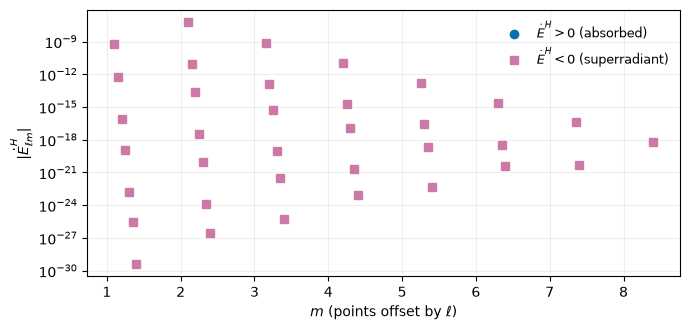

In [4]:
orbN = MiniGeo(0.0, 500.0, 0.0, 1.0)
modesN = [(l, m) for l in (2, 3, 4) for m in range(1, l + 1)]
lN = np.array([c[0] for c in modesN]); mN = np.array([c[1] for c in modesN])
solN = solve_mode_table(orbN, -2, lN, mN, np.zeros_like(lN))
fxN = flux_modes(solN.amplitudes, solN.m, solN.omega, solN.eigenvalues, 0.0)
total = 2 * float(np.asarray(fxN.Edot)[:, 0].sum())
newt = 32.0 / 5.0 * orbN.frequencies[2] ** (10.0 / 3.0)
assert abs(total / newt - 1) < 2e-2
print(f"p = 500: total/quadrupole = {total/newt:.5f}  (1PN residual ~ 1/p)")

orbS = MiniGeo(0.9, 10.0, 0.0, 1.0)
modesS = [(l, m) for l in range(2, 9) for m in range(1, l + 1)]
lS = np.array([c[0] for c in modesS]); mS = np.array([c[1] for c in modesS])
solS = solve_mode_table(orbS, -2, lS, mS, np.zeros_like(lS))
fxS = flux_modes(solS.amplitudes, solS.m, solS.omega, solS.eigenvalues, orbS.a)
EH = np.asarray(fxS.Edot)[:, 1]
OmegaH = orbS.a / (2 * (1 + np.sqrt(1 - orbS.a**2)))
super_pred = np.asarray(solS.omega) < mS * OmegaH
assert np.all((EH < 0) == super_pred)
print(f"superradiant modes: {int(super_pred.sum())}/{len(mS)} "
      f"(all with omega < m Omega_H, as predicted)")

fig, ax = plt.subplots(figsize=(7, 3.4))
sr, nr = super_pred, ~super_pred
ax.semilogy(mS[nr] + 0.05 * lS[nr], EH[nr], "o", color=C[0],
            label=r"$\dot{E}^H > 0$ (absorbed)")
ax.semilogy(mS[sr] + 0.05 * lS[sr], -EH[sr], "s", color=C[3],
            label=r"$\dot{E}^H < 0$ (superradiant)")
ax.set_xlabel(r"$m$ (points offset by $\ell$)")
ax.set_ylabel(r"$|\dot{E}^H_{\ell m}|$")
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=0.2)
plt.tight_layout()

## Summary

1. hblteuk complex amplitudes ≡ pybhpt (< 1e-7, both families) — the
   normalization gate for all flux work
2. all four flux channels match pybhpt per mode
3. quadrupole limit and superradiance behave as physics demands

Next increments (`dev/PHASE5_PLAN.md`): spherical-inclined orbits (1D
$q_\theta$ Fourier), then generic orbits (2D torus).